# 3.5 — Brightness and contrast measurements
Demonstrate the two independent CV criteria using standardized RGB inputs. These are whole-image measurements, not brand scores or proof of subject readability.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from brandlens.analysis.brightness_contrast import (
    MeasurementSettings,
    measure_brightness,
    measure_contrast,
)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config" / "brand_standards.json").is_file()), Path.cwd())
CONFIG_PATH = ROOT / "config" / "brand_standards.json"

## 1. Measurement settings from the brand configuration
Read each criterion separately so its cutoffs can differ. If no configuration is found, use clearly labeled demonstration defaults. Evaluation limits (such as `mean_luminance_min`) do not enter these functions. The implementation supports only the 0–255 intensity scale.

In [2]:
if CONFIG_PATH.is_file():
    config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
    criteria = {item["criterion_id"]: item for item in config["criteria"]}
    settings_by_criterion = {}
    for criterion_id in ("exposure_brightness", "contrast"):
        params = criteria[criterion_id]["params"]
        if params.get("luminance_scale", 255) != 255:
            raise ValueError("This implementation requires luminance_scale=255.")
        settings_by_criterion[criterion_id] = MeasurementSettings(
            near_black_max=params["near_black_max"],
            near_white_min=params["near_white_min"],
        )
    print("Configuration:", CONFIG_PATH)
    print("Rubric:", config.get("rubric_id", "not specified"))
else:
    settings_by_criterion = {
        "exposure_brightness": MeasurementSettings(),
        "contrast": MeasurementSettings(),
    }
    print("DEMO DEFAULTS: brand_standards.json was not found.")

for criterion_id, settings in settings_by_criterion.items():
    print(criterion_id, settings.to_dict())

Configuration: f:\V_Tech Semesters\MS Thesis\Jupyter_MS\git\visual-brand-audit\config\brand_standards.json
Rubric: default-v1-draft
exposure_brightness {'near_black_max': 10, 'near_white_min': 245}
contrast {'near_black_max': 10, 'near_white_min': 245}


## 2. Synthetic RGB samples
All samples are already RGB with neutral channel values. The full ramp contains each intensity from 0 to 255 equally often; the boundary sample includes values immediately around both default cutoffs.

In [3]:
def rgb_from_gray(array):
    return Image.fromarray(np.repeat(np.asarray(array, dtype=np.uint8)[..., None], 3, axis=2))

ramp = np.tile(np.arange(256, dtype=np.uint8), (128, 1))
samples = [
    {"name": "Black", "image": Image.new("RGB", (256, 128), (0, 0, 0))},
    {"name": "White", "image": Image.new("RGB", (256, 128), (255, 255, 255))},
    {"name": "Uniform gray 128", "image": Image.new("RGB", (256, 128), (128, 128, 128))},
    {"name": "Equal black / white", "image": rgb_from_gray(np.tile(np.repeat([0, 255], 128), (128, 1)))},
    {"name": "Full gradient", "image": rgb_from_gray(ramp)},
    {"name": "Low contrast gradient", "image": rgb_from_gray(110 + (ramp.astype(float) * 30 / 255).round())},
    {"name": "Cutoff boundaries", "image": rgb_from_gray(np.tile(np.repeat([9, 10, 11, 244, 245, 246], 40), (128, 1)))},
]

def analyze(image):
    return {
        "exposure_brightness": measure_brightness(image, settings_by_criterion["exposure_brightness"]),
        "contrast": measure_contrast(image, settings_by_criterion["contrast"]),
    }

results = {sample["name"]: analyze(sample["image"]) for sample in samples}

## 3. Display every sample and its measurements
Each row shows the image and its intensity histogram. Dashed lines show brightness cutoffs; dotted lines show contrast cutoffs. Images are scaled for display only.

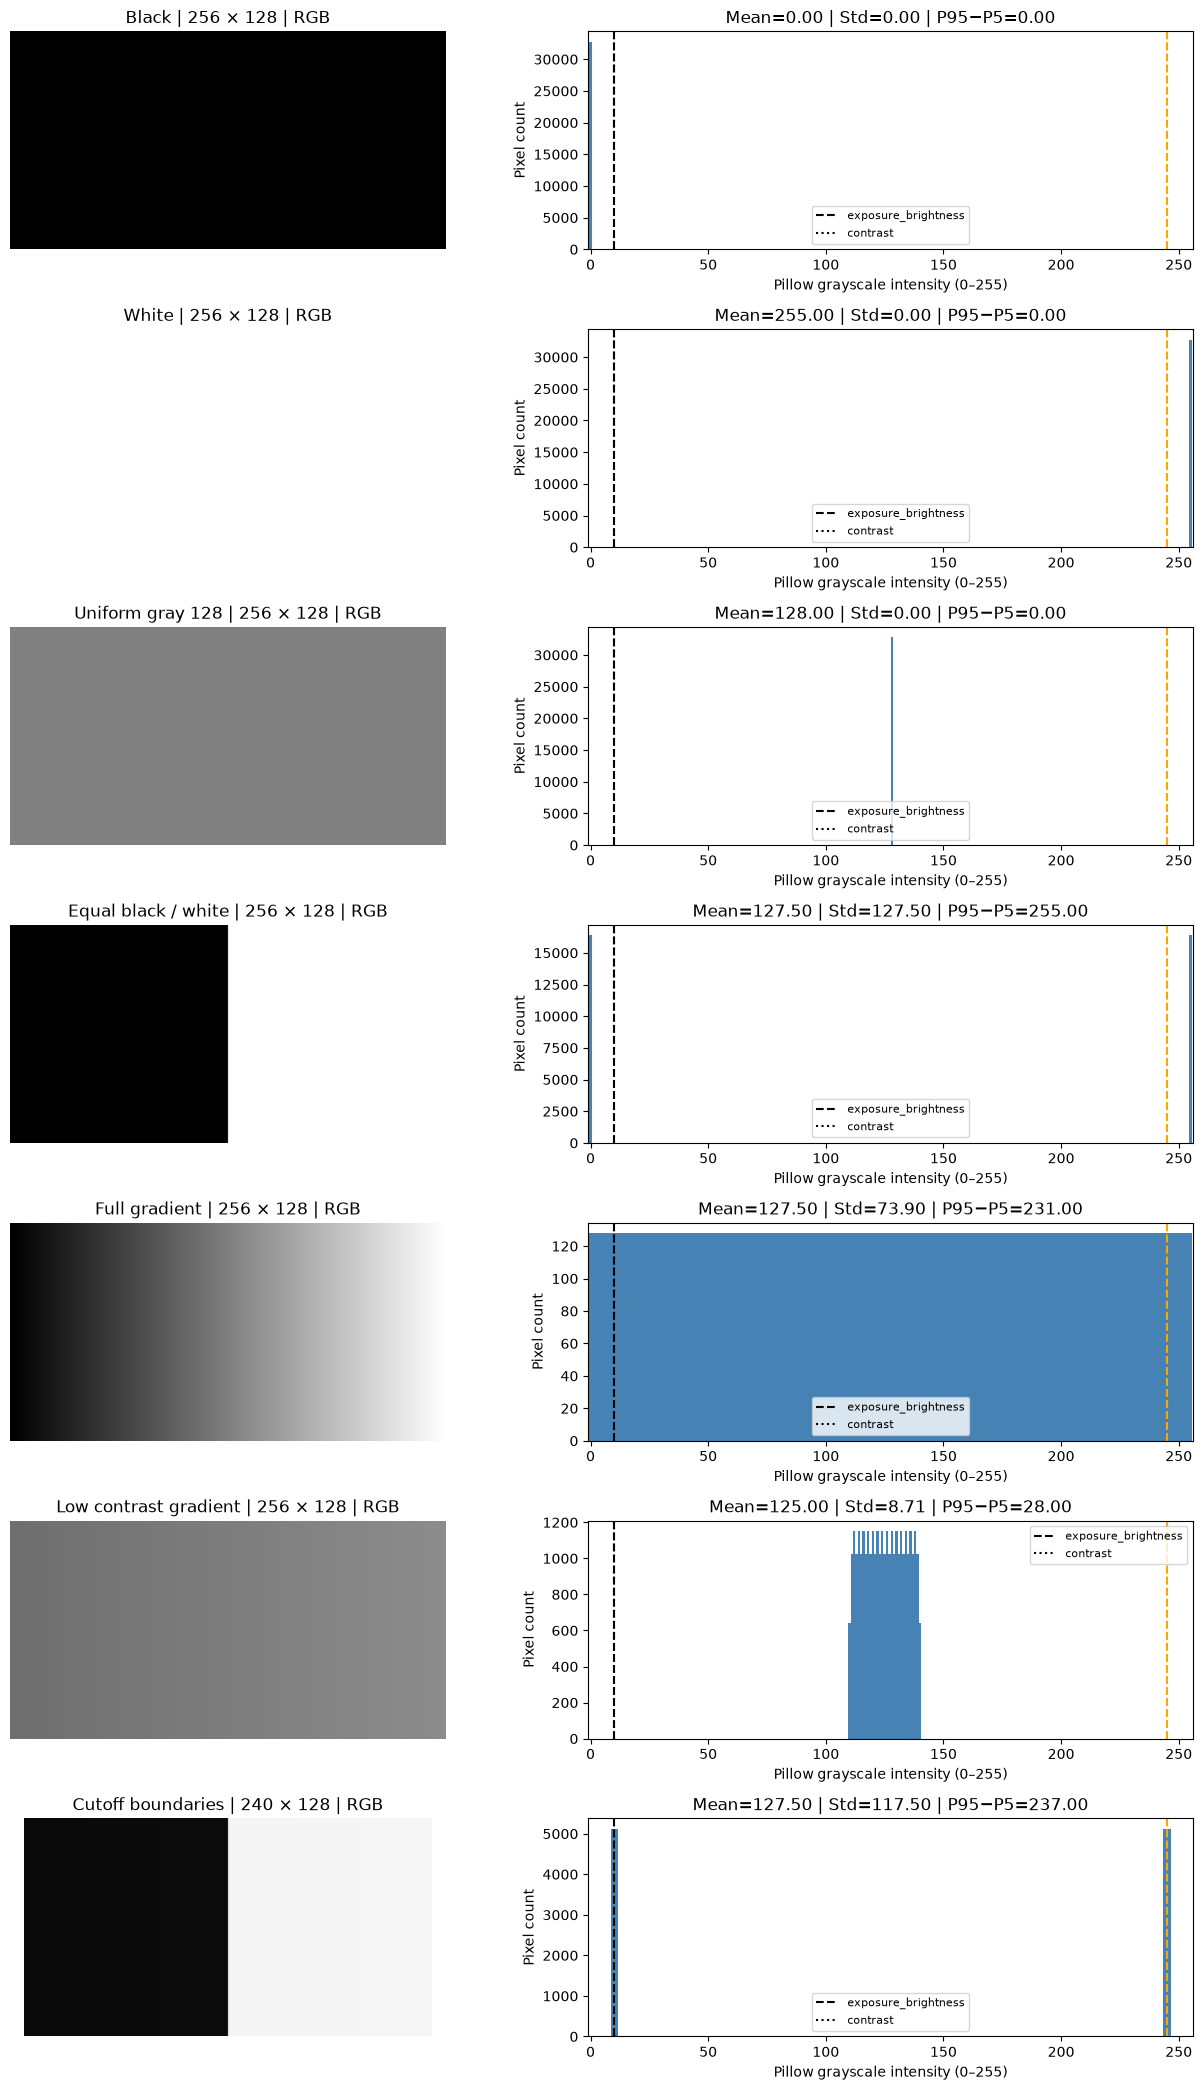

| Sample | Mean | Std | P95−P5 | Brightness black / white | Contrast black / white |
|---|---:|---:|---:|---:|---:|
| Black | 0.00 | 0.00 | 0.00 | 1.000 / 0.000 | 1.000 / 0.000 |
| White | 255.00 | 0.00 | 0.00 | 0.000 / 1.000 | 0.000 / 1.000 |
| Uniform gray 128 | 128.00 | 0.00 | 0.00 | 0.000 / 0.000 | 0.000 / 0.000 |
| Equal black / white | 127.50 | 127.50 | 255.00 | 0.500 / 0.500 | 0.500 / 0.500 |
| Full gradient | 127.50 | 73.90 | 231.00 | 0.043 / 0.043 | 0.043 / 0.043 |
| Low contrast gradient | 125.00 | 8.71 | 28.00 | 0.000 / 0.000 | 0.000 / 0.000 |
| Cutoff boundaries | 127.50 | 117.50 | 237.00 | 0.333 / 0.333 | 0.333 / 0.333 |


In [4]:
def show_samples(items):
    fig, axes = plt.subplots(len(items), 2, figsize=(13, 3 * len(items)), squeeze=False)
    for row, sample in enumerate(items):
        image = sample["image"]
        result = analyze(image)
        brightness, contrast = result["exposure_brightness"], result["contrast"]
        axes[row, 0].imshow(image)
        axes[row, 0].set_title(f"{sample['name']} | {image.width} × {image.height} | {image.mode}")
        axes[row, 0].axis("off")
        ax = axes[row, 1]
        intensity = np.asarray(image.convert("L"))
        ax.hist(intensity.ravel(), bins=np.arange(257) - 0.5, color="steelblue")
        for criterion_id, style in (("exposure_brightness", "--"), ("contrast", ":")):
            settings = settings_by_criterion[criterion_id]
            ax.axvline(settings.near_black_max, color="black", linestyle=style, label=criterion_id)
            ax.axvline(settings.near_white_min, color="orange", linestyle=style)
        ax.set(xlim=(-1, 256), xlabel="Pillow grayscale intensity (0–255)", ylabel="Pixel count")
        ax.set_title(f"Mean={brightness['mean_luminance']:.2f} | Std={contrast['luminance_std']:.2f} | P95−P5={contrast['p5_p95_range']:.2f}")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

def show_table(items):
    lines = ["| Sample | Mean | Std | P95−P5 | Brightness black / white | Contrast black / white |",
             "|---|---:|---:|---:|---:|---:|"]
    for sample in items:
        result = analyze(sample["image"])
        b, c = result["exposure_brightness"], result["contrast"]
        lines.append(f"| {sample['name']} | {b['mean_luminance']:.2f} | {c['luminance_std']:.2f} | {c['p5_p95_range']:.2f} | {b['near_black_fraction']:.3f} / {b['near_white_fraction']:.3f} | {c['near_black_fraction']:.3f} / {c['near_white_fraction']:.3f} |")
    print("\n".join(lines))

show_samples(samples)
show_table(samples)

## 4. Known-answer checks
These checks explicitly use default settings, independently of your brand file. Population standard deviation uses `ddof=0`; percentiles use linear interpolation. For only two pixels [10, 50], P5=12 and P95=48.

In [5]:
defaults = MeasurementSettings()
assert measure_brightness(samples[0]["image"], defaults)["mean_luminance"] == 0.0
assert measure_brightness(samples[1]["image"], defaults)["mean_luminance"] == 255.0
assert measure_contrast(samples[2]["image"], defaults)["luminance_std"] == 0.0
assert measure_brightness(samples[3]["image"], defaults)["mean_luminance"] == 127.5
assert measure_contrast(samples[3]["image"], defaults)["luminance_std"] == 127.5
assert measure_contrast(samples[3]["image"], defaults)["p5_p95_range"] == 255.0
with rgb_from_gray([[10, 50]]) as tiny:
    assert measure_contrast(tiny)["luminance_std"] == 20.0
    assert np.isclose(measure_contrast(tiny)["p5_p95_range"], 36.0)
for sample in samples:
    before = sample["image"].tobytes()
    assert analyze(sample["image"]) == analyze(sample["image"])
    assert sample["image"].tobytes() == before
print("Known-answer, repeatability, and pixel-preservation checks passed.")

Known-answer, repeatability, and pixel-preservation checks passed.


## 5. Changing measurement cutoffs
Changing the pixel cutoffs changes the fractions, so remeasurement is necessary. It does not change mean intensity, standard deviation, or percentile spread. Changing evaluation thresholds alone would not require remeasurement.

In [6]:
image = samples[4]["image"]
for settings in (MeasurementSettings(10, 245), MeasurementSettings(30, 225)):
    print("Cutoffs:", settings.to_dict())
    print(json.dumps({"exposure_brightness": measure_brightness(image, settings),
                      "contrast": measure_contrast(image, settings)}, indent=2))

Cutoffs: {'near_black_max': 10, 'near_white_min': 245}
{
  "exposure_brightness": {
    "mean_luminance": 127.5,
    "near_black_fraction": 0.04296875,
    "near_white_fraction": 0.04296875
  },
  "contrast": {
    "luminance_std": 73.90027063549903,
    "p5_p95_range": 231.0,
    "near_black_fraction": 0.04296875,
    "near_white_fraction": 0.04296875
  }
}
Cutoffs: {'near_black_max': 30, 'near_white_min': 225}
{
  "exposure_brightness": {
    "mean_luminance": 127.5,
    "near_black_fraction": 0.12109375,
    "near_white_fraction": 0.12109375
  },
  "contrast": {
    "luminance_std": 73.90027063549903,
    "p5_p95_range": 231.0,
    "near_black_fraction": 0.12109375,
    "near_white_fraction": 0.12109375
  }
}


## 6. Optional: your photographs
Add file paths below. This section uses the existing loading and standardization modules before measurement; it does not apply the geometry filter. `max_size=None` preserves resolution. To demonstrate deployed pipeline behavior, use the same resize settings as that pipeline: resizing can change the measurements.

In [7]:
IMAGE_PATHS = [
    # ROOT / "examples" / "data" / "photo.jpg",
]

if IMAGE_PATHS:
    from brandlens.preprocessing.image_io import load_image
    from brandlens.preprocessing.standardization import StandardizationSettings, standardize_image

    real_samples = []
    try:
        for path in IMAGE_PATHS:
            with load_image(path) as original:
                processed = standardize_image(original, StandardizationSettings(max_size=None))
            real_samples.append({"name": Path(path).name, "image": processed})
        show_samples(real_samples)
        show_table(real_samples)
    finally:
        for sample in real_samples:
            sample["image"].close()
else:
    print("Add image paths above to run the real-photo demonstration.")

Add image paths above to run the real-photo demonstration.


Notes
- Mean intensity: 0–255; population standard deviation: 0–127.5; P95−P5: 0–255; fractions: 0–1.
- “Luminance” keys use Pillow's rounded grayscale proxy, not physical linear-light luminance.
- Global metrics do not locate subjects or prove subject/background separation.
- Near-black and near-white pixels can be intentional; these fractions do not by themselves prove exposure clipping.
- Placeholder brand thresholds are not validated scoring rules. No pass/fail or brand scores are assigned here.